<a href="https://colab.research.google.com/github/Shashank-sketchAl/ML-90-Day-Challenge-/blob/main/Day22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##K Means Clustering

In [1]:
import pandas as pd


In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Mall_Customers.csv")

print(df.head())
print(df.shape)

Saving Mall_Customers.csv to Mall_Customers.csv
   CustomerID  Gender   Age   Annual Income (k$)   Spending Score (1-100)
0           1    Male    19                   15                       39
1           2    Male    21                   15                       81
2           3  Female    20                   16                        6
3           4  Female    23                   16                       77
4           5  Female    31                   17                       40
(200, 5)


In [3]:
print("Shape:",df.shape)
print(df.info())
print(df.isnull().sum())
print("Total Duplicated values in this :",df.duplicated().sum())
print(df.describe())

Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   CustomerID               200 non-null    int64 
 1    Gender                  200 non-null    object
 2    Age                     200 non-null    int64 
 3    Annual Income (k$)      200 non-null    int64 
 4    Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
CustomerID                 0
 Gender                    0
 Age                       0
 Annual Income (k$)        0
 Spending Score (1-100)    0
dtype: int64
Total Duplicated values in this : 0
       CustomerID         Age   Annual Income (k$)   Spending Score (1-100)
count  200.000000  200.000000           200.000000               200.000000
mean   100.500000   38.850000            60.560000                50.200000
std     57.879185   13.969007   

In [4]:
print(df.columns.tolist())

['CustomerID', ' Gender', ' Age', ' Annual Income (k$)', ' Spending Score (1-100)']


In [5]:
X = df[[" Annual Income (k$)"," Spending Score (1-100)"]]
print(X.head())

   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40


In [6]:
print("Feature shape:",X.shape)

Feature shape: (200, 2)


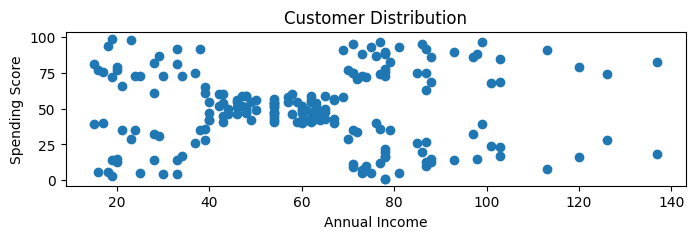

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,2))

plt.scatter(
    X[" Annual Income (k$)"],
    X[" Spending Score (1-100)"]
)
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Distribution")

plt.show()

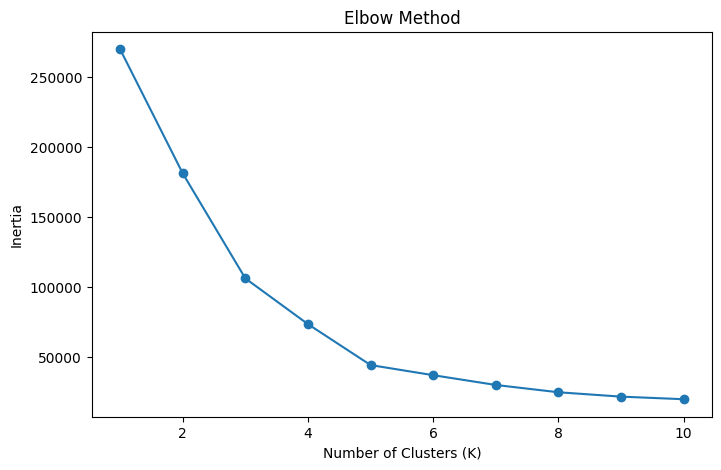

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
for k in range(1,11):
  kmeans= KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
  )
  kmeans.fit(X)
  inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia_values, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [11]:
from sklearn.cluster import KMeans
kmeans  = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)
kmeans.fit(X)

df["Cluster"]=kmeans.labels_
print(df.head())

   CustomerID  Gender   Age   Annual Income (k$)   Spending Score (1-100)  \
0           1    Male    19                   15                       39   
1           2    Male    21                   15                       81   
2           3  Female    20                   16                        6   
3           4  Female    23                   16                       77   
4           5  Female    31                   17                       40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  


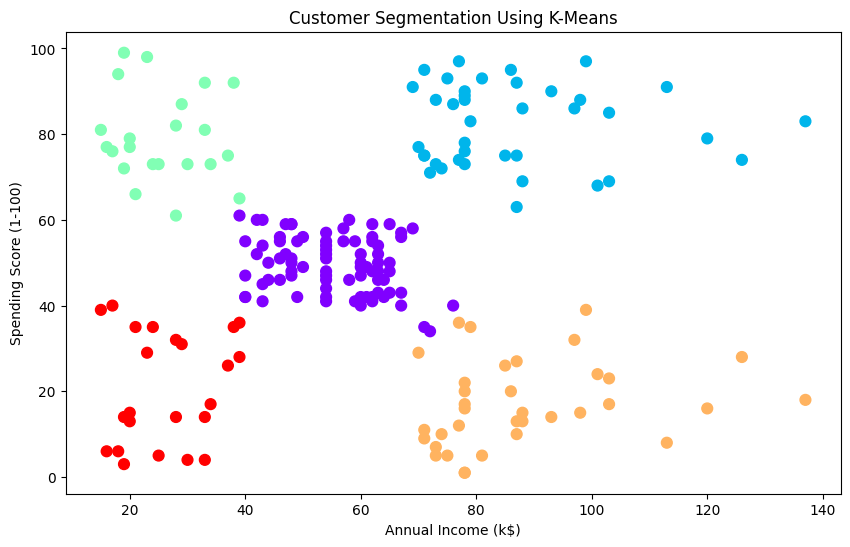

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))

plt.scatter(
    X[" Annual Income (k$)"],
    X[" Spending Score (1-100)"],
    c=df["Cluster"],
    cmap="rainbow",
    s=60
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Customer Segmentation Using K-Means")

plt.show()

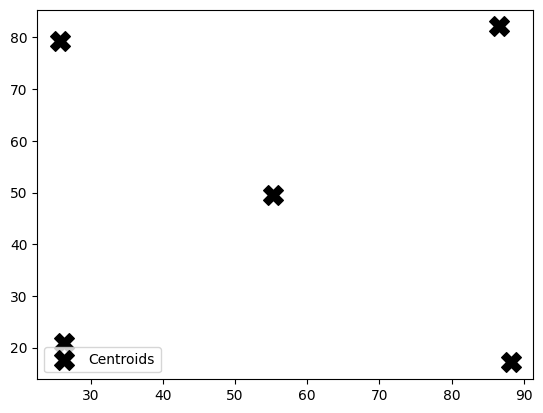

In [15]:
centroids = kmeans.cluster_centers_
plt.scatter(centroids[:,0],centroids[:,1],color="black",marker="X",s=200,label="Centroids")

plt.legend()
plt.show()

In [16]:
print("Centroid coordinates:")

for i, centroid in enumerate(kmeans.cluster_centers_):
  print(f"Cluster {i}: Income = {centroid[0]:.2f}, Spending Score = {centroid[1]:.2f}")

Centroid coordinates:
Cluster 0: Income = 55.30, Spending Score = 49.52
Cluster 1: Income = 86.54, Spending Score = 82.13
Cluster 2: Income = 25.73, Spending Score = 79.36
Cluster 3: Income = 88.20, Spending Score = 17.11
Cluster 4: Income = 26.30, Spending Score = 20.91


In [17]:
print(df["Cluster"].value_counts().sort_index())

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64
